# <span style="color: #a855f7">Data preprocessing</span>

<span style="color: #a855f7">EDA, пропуски, кодування категорій, окремі pipeline для числових і категоріальних ознак, перевірка результатів на train/test</span>

In [1]:
from html import escape

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import HTML, display
from sklearn.compose import ColumnTransformer
from sklearn.datasets import fetch_openml
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.utils import Bunch

PURPLE = "#a855f7"
PINK = "#f472b6"
BLUE = "#60a5fa"
YELLOW = "#facc15"


def colorize(value, *, index=True):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        table = value.to_frame() if isinstance(value, pd.Series) else value
        html = table.to_html(border=0, index=index).replace(
            '<table ', '<table style="color: #a855f7; margin-left: 0; margin-right: auto; border-collapse: collapse" '
        )
        for tag in ("th", "td"):
            html = html.replace(
                f"<{tag}>",
                f'<{tag} style="padding: 6px 12px; border-bottom: 1px solid #746a80">',
            )
        display(HTML(html))
    else:
        display(HTML(f'<pre style="color: #a855f7; background: transparent">{escape(str(value))}</pre>'))


def load_openml_frame(data_id, *, parser="auto"):
    dataset = fetch_openml(data_id=data_id, as_frame=True, return_X_y=False, parser=parser)
    if not isinstance(dataset, Bunch) or not isinstance(dataset.frame, pd.DataFrame):
        raise TypeError("Expected an OpenML dataset with a pandas DataFrame")
    return dataset.frame.copy()


plt.style.use("dark_background")
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 110,
    "figure.facecolor": "#111116",
    "axes.facecolor": "#111116",
    "axes.edgecolor": "#746a80",
    "axes.labelcolor": "#e9d5ff",
    "axes.titlecolor": "#e9d5ff",
    "axes.titlesize": 13,
    "text.color": "#e9d5ff",
    "xtick.color": "#d8c8ed",
    "ytick.color": "#d8c8ed",
    "grid.color": "#746a80",
    "grid.alpha": 0.25,
    "lines.linewidth": 2,
    "font.size": 10,
})

## <span style="color: #a855f7">Titanic overview</span>

<span style="color: #a855f7">OpenML dataset 40945, перше завантаження потребує інтернету, потім використовується кеш scikit-learn, один рядок - пасажир, Survived: 0 - не вижив, 1 - вижив</span>

In [2]:
titanic = load_openml_frame(40945, parser="liac-arff").rename(columns={
    "pclass": "Pclass", "survived": "Survived", "name": "Name", "sex": "Sex",
    "age": "Age", "sibsp": "SibSp", "parch": "Parch", "ticket": "Ticket",
    "fare": "Fare", "cabin": "Cabin", "embarked": "Embarked", "boat": "Boat",
    "body": "Body", "home.dest": "HomeDestination",
})
required_columns = {"Survived", "Pclass", "Age", "Fare", "Sex", "SibSp", "Parch", "Boat", "Body"}
if not required_columns.issubset(titanic.columns):
    raise ValueError("Titanic is missing required columns")
titanic["Survived"] = pd.to_numeric(titanic["Survived"], errors="raise").astype(int)
if titanic["Survived"].isna().any() or set(titanic["Survived"].unique()) != {0, 1}:
    raise ValueError("Survived must contain both binary classes without missing values")
titanic[["Pclass", "SibSp", "Parch"]] = titanic[["Pclass", "SibSp", "Parch"]].astype(int)
colorize(f"rows: {len(titanic)} | columns: {titanic.shape[1]} | duplicate rows: {titanic.duplicated().sum()}")
colorize("First 5 rows")
colorize(titanic.head())
titanic_schema = pd.DataFrame({
    "column": titanic.columns,
    "dtype": titanic.dtypes.astype(str).to_numpy(),
    "non-null": titanic.notna().sum().to_numpy(),
    "missing": titanic.isna().sum().to_numpy(),
})
colorize("Column structure")
colorize(titanic_schema, index=False)
colorize("Numeric summary")
colorize(titanic.describe().round(3))

,Pclass,Survived,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Boat,Body,HomeDestination
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"


column,dtype,non-null,missing
Pclass,int64,1309,0
Survived,int64,1309,0
Name,str,1309,0
Sex,category,1309,0
Age,float64,1046,263
SibSp,int64,1309,0
Parch,int64,1309,0
Ticket,str,1309,0
Fare,float64,1308,1
Cabin,str,295,1014


,Pclass,Survived,Age,SibSp,Parch,Fare,Body
count,1309.000,1309.000,1046.000,1309.000,1309.000,1308.000,121.000
mean,2.295,0.382,29.881,0.499,0.385,33.295,160.810
std,0.838,0.486,14.413,1.042,0.866,51.759,97.697
min,1.000,0.000,0.167,0.000,0.000,0.000,1.000
25%,2.000,0.000,21.000,0.000,0.000,7.896,72.000
50%,3.000,0.000,28.000,0.000,0.000,14.454,155.000
75%,3.000,1.000,39.000,1.000,0.000,31.275,256.000
max,3.000,1.000,80.000,8.000,9.000,512.329,328.000


## <span style="color: #a855f7">Missing values</span>

<span style="color: #a855f7">к-сть і відсоток пропусків у всіх колонках, графік показує лише колонки з пропусками, Boat і Body описують події після катастрофи, тому далі не використовуються як ознаки виживання</span>

column,missing,missing (%)
Body,1188,90.76
Cabin,1014,77.46
Boat,823,62.87
HomeDestination,564,43.09
Age,263,20.09
Embarked,2,0.15
Fare,1,0.08
SibSp,0,0.00
Name,0,0.00
Survived,0,0.00


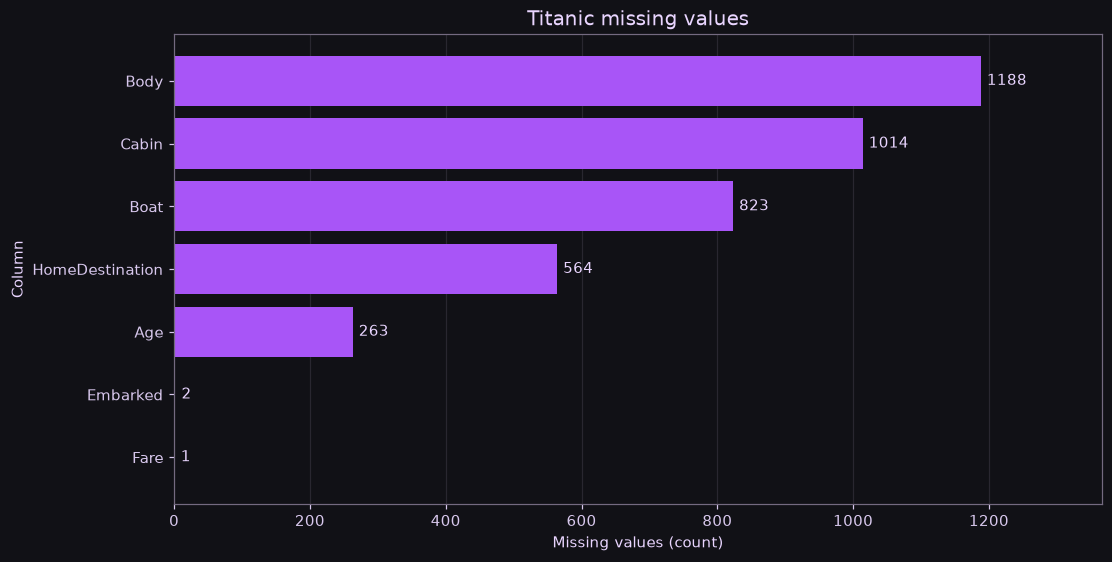

In [3]:
missing_counts = titanic.isna().sum().sort_values(ascending=False)
missing_summary = pd.DataFrame({
    "column": missing_counts.index,
    "missing": missing_counts.to_numpy(),
    "missing (%)": (missing_counts / len(titanic) * 100).round(2).to_numpy(),
})
colorize(missing_summary, index=False)
missing_plot = missing_summary.loc[missing_summary["missing"] > 0].sort_values("missing")
fig, ax = plt.subplots(layout="constrained")
bars = ax.barh(missing_plot["column"].tolist(), missing_plot["missing"].to_numpy(), color=PURPLE)
ax.bar_label(bars, padding=4)
ax.set(title="Titanic missing values", xlabel="Missing values (count)", ylabel="Column")
ax.set_xlim(0, missing_plot["missing"].max() * 1.15)
ax.grid(axis="x")
ax.set_axisbelow(True)
plt.show()

## <span style="color: #a855f7">Survival distribution</span>

<span style="color: #a855f7">к-сть і частка двох класів цільової змінної, дисбаланс класів враховується під час інтерпретації результатів</span>

Survived,count,share (%)
0,809,61.8
1,500,38.2


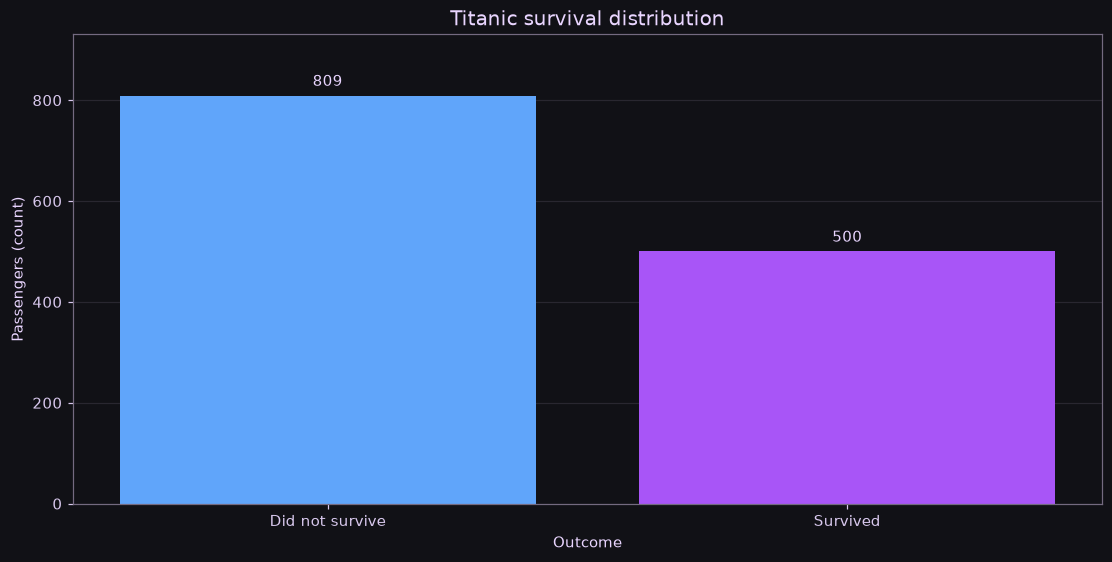

In [4]:
survival_counts = titanic["Survived"].value_counts().sort_index()
survival_summary = pd.DataFrame({
    "Survived": survival_counts.index,
    "count": survival_counts.to_numpy(),
    "share (%)": (survival_counts / len(titanic) * 100).round(2).to_numpy(),
})
colorize(survival_summary, index=False)
fig, ax = plt.subplots(layout="constrained")
bars = ax.bar(["Did not survive", "Survived"], survival_counts.to_numpy(), color=[BLUE, PURPLE])
ax.bar_label(bars, padding=4)
ax.set(title="Titanic survival distribution", xlabel="Outcome", ylabel="Passengers (count)")
ax.set_ylim(0, survival_counts.max() * 1.15)
ax.grid(axis="y")
ax.set_axisbelow(True)
plt.show()

## <span style="color: #a855f7">Age distribution</span>

<span style="color: #a855f7">гістограма наявних значень Age, лінії avg і median, пропуски не заповнюються штучно для EDA</span>

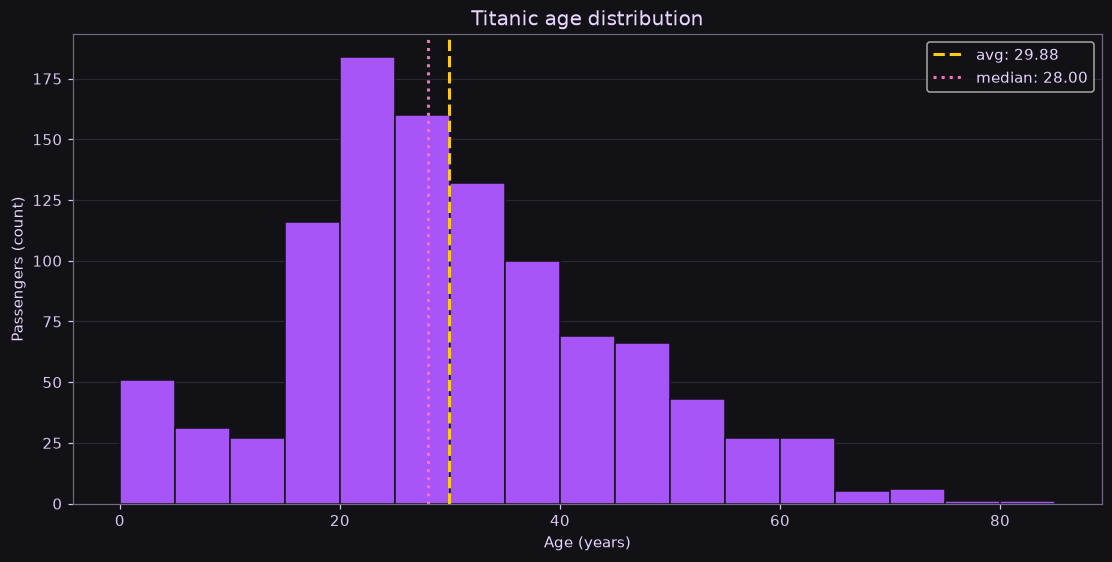

In [5]:
known_ages = titanic["Age"].dropna()
fig, ax = plt.subplots(layout="constrained")
ax.hist(known_ages.to_numpy(), bins=list(range(0, 86, 5)), color=PURPLE, edgecolor="#111116")
ax.axvline(known_ages.mean(), color=YELLOW, linestyle="--", label=f"avg: {known_ages.mean():.2f}")
ax.axvline(known_ages.median(), color=PINK, linestyle=":", label=f"median: {known_ages.median():.2f}")
ax.set(title="Titanic age distribution", xlabel="Age (years)", ylabel="Passengers (count)")
ax.legend()
ax.grid(axis="y")
ax.set_axisbelow(True)
plt.show()

## <span style="color: #a855f7">Survival by ticket class</span>

<span style="color: #a855f7">частка виживання за Pclass, для порівняння використовуються відсотки, бо к-сть пасажирів у класах різна</span>

,passengers,survived,survival (%)
Pclass,,,
1,323,200,61.92
2,277,119,42.96
3,709,181,25.53


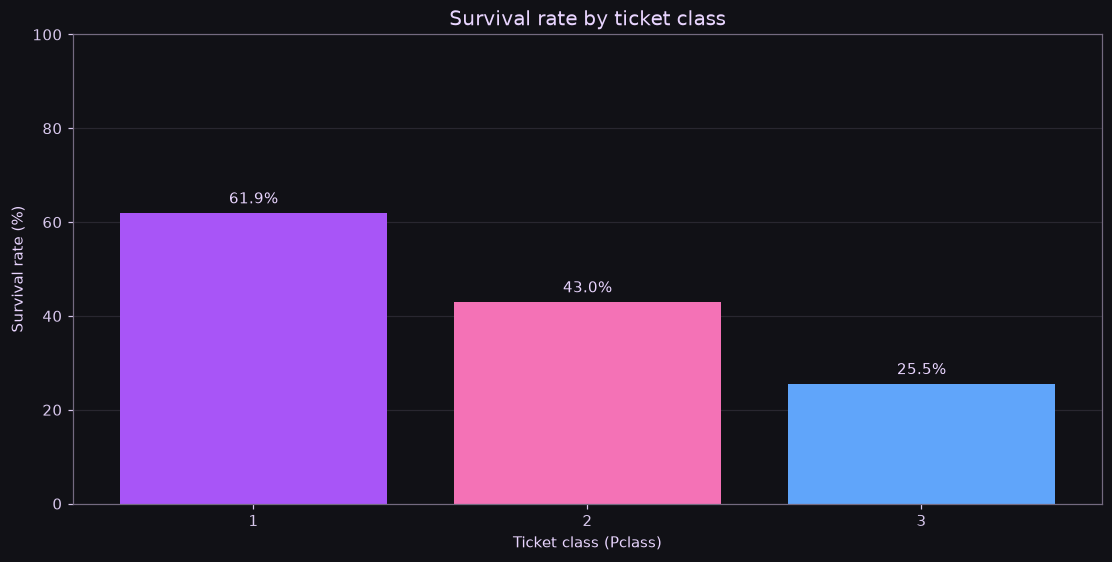

In [6]:
class_summary = titanic.groupby("Pclass")["Survived"].agg(passengers="size", survived="sum", survival_rate="mean")
class_summary["survival (%)"] = class_summary.pop("survival_rate") * 100
colorize(class_summary.round(2))
fig, ax = plt.subplots(layout="constrained")
bars = ax.bar(class_summary.index.astype(str).tolist(), class_summary["survival (%)"].to_numpy(), color=[PURPLE, PINK, BLUE])
ax.bar_label(bars, labels=[f"{value:.1f}%" for value in class_summary["survival (%)"]], padding=4)
ax.set(title="Survival rate by ticket class", xlabel="Ticket class (Pclass)", ylabel="Survival rate (%)", ylim=(0, 100))
ax.grid(axis="y")
ax.set_axisbelow(True)
plt.show()

## <span style="color: #a855f7">Age by survival outcome</span>

<span style="color: #a855f7">boxplot порівнює median і розкид віку двох груп, окремі точки поза вусами - статистичні викиди</span>

,count,avg,median,min,max
Survived,,,,,
0,619,30.55,28.0,0.33,74.0
1,427,28.92,28.0,0.17,80.0


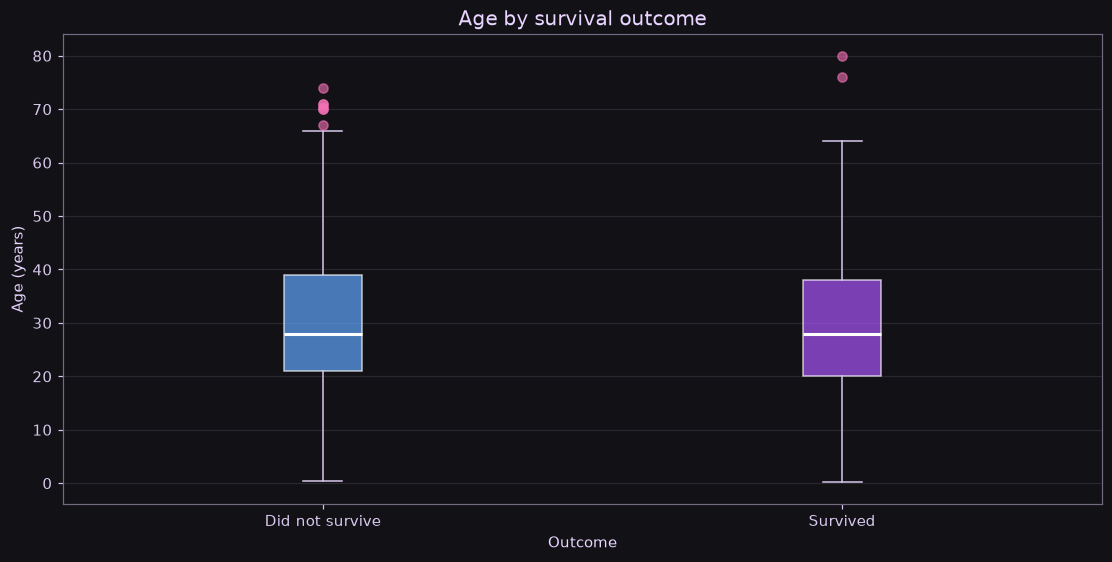

In [7]:
age_groups = [titanic.loc[titanic["Survived"] == outcome, "Age"].dropna().to_numpy() for outcome in (0, 1)]
colorize(titanic.groupby("Survived")["Age"].agg(count="count", avg="mean", median="median", min="min", max="max").round(2))
fig, ax = plt.subplots(layout="constrained")
boxes = ax.boxplot(
    age_groups, tick_labels=["Did not survive", "Survived"], patch_artist=True,
    medianprops={"color": "#ffffff", "linewidth": 2},
    whiskerprops={"color": "#d8c8ed"}, capprops={"color": "#d8c8ed"},
    flierprops={"marker": "o", "markerfacecolor": PINK, "markeredgecolor": PINK, "alpha": 0.6},
)
for box, color in zip(boxes["boxes"], [BLUE, PURPLE], strict=True):
    box.set_facecolor(color)
    box.set_alpha(0.7)
ax.set(title="Age by survival outcome", xlabel="Outcome", ylabel="Age (years)")
ax.grid(axis="y")
ax.set_axisbelow(True)
plt.show()

## <span style="color: #a855f7">Survival correlations</span>

<span style="color: #a855f7">Pearson-кореляції числових ознак і бінарної ознаки Female: 1 - female, 0 - male, Boat і Body виключені через витік відповіді, пропуски обробляються попарно методом corr, кореляція не доводить причинність</span>

,Survived
Female,0.5287
Pclass,-0.3125
Fare,0.2443
Parch,0.0827
Age,-0.0555
SibSp,-0.0278


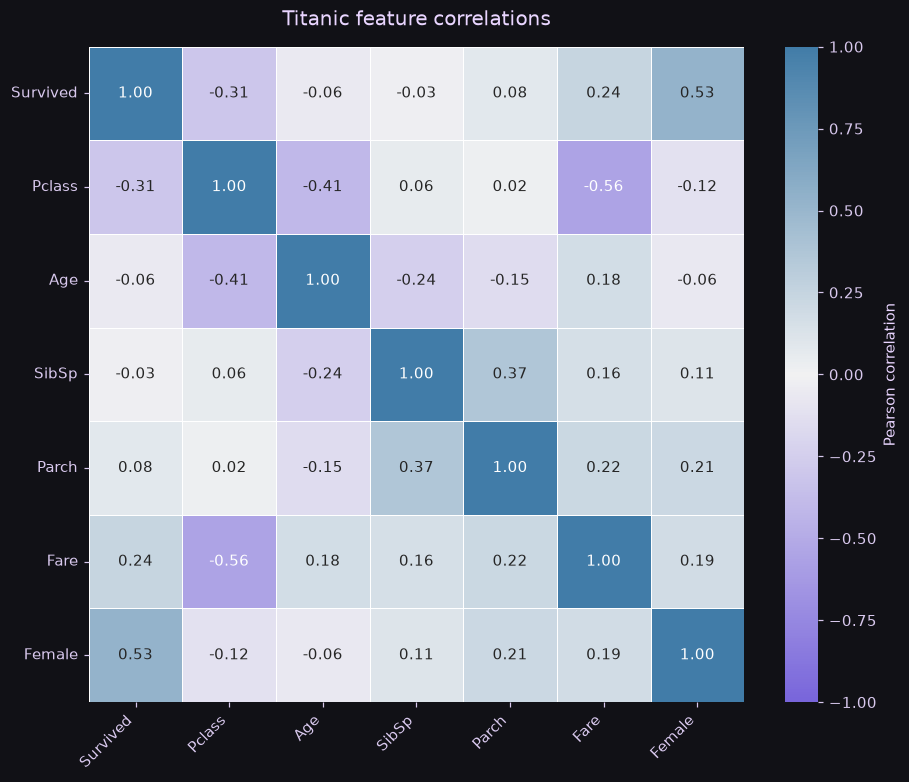

In [8]:
correlation_data = titanic[["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]].copy()
correlation_data["Female"] = titanic["Sex"].map({"female": 1, "male": 0}).astype(int)
correlation_matrix = correlation_data.corr()
survival_correlations = correlation_matrix["Survived"].drop("Survived").sort_values(key=abs, ascending=False)
colorize("Correlations with Survived")
colorize(survival_correlations.round(4))
fig, ax = plt.subplots(figsize=(9, 7), layout="constrained")
sns.heatmap(
    correlation_matrix, annot=True, fmt=".2f", vmin=-1, vmax=1, center=0,
    cmap=sns.diverging_palette(270, 240, as_cmap=True), square=True,
    linewidths=0.5, cbar_kws={"label": "Pearson correlation"}, ax=ax,
)
ax.set_title("Titanic feature correlations", pad=14)
ax.tick_params(axis="x", labelrotation=45)
ax.tick_params(axis="y", labelrotation=0)
plt.setp(ax.get_xticklabels(), ha="right")
plt.show()

## <span style="color: #a855f7">Age and fare</span>

<span style="color: #a855f7">scatter використовує лише рядки з відомими Age і Fare, колір позначає виживання, дані з великим Fare залишені для аналізу розподілу і викидів</span>

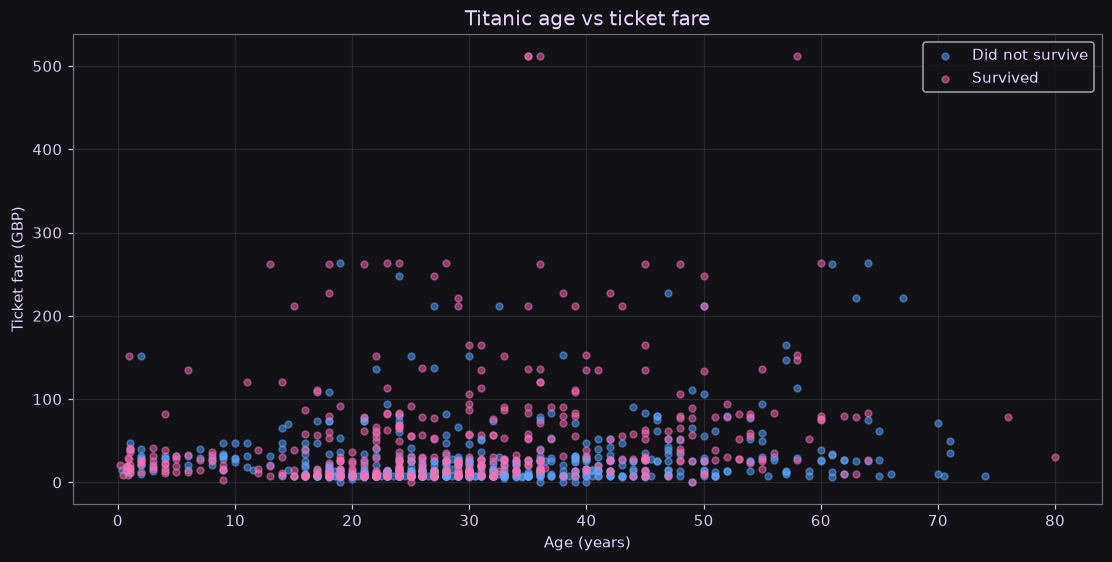

In [9]:
scatter_data = titanic.dropna(subset=["Age", "Fare"])
colorize(f"plotted rows: {len(scatter_data)} | excluded due to missing Age/Fare: {len(titanic) - len(scatter_data)}")
fig, ax = plt.subplots(layout="constrained")
for outcome, label, color in [(0, "Did not survive", BLUE), (1, "Survived", PINK)]:
    group = scatter_data.loc[scatter_data["Survived"] == outcome]
    ax.scatter(group["Age"].to_numpy(), group["Fare"].to_numpy(), color=color, s=20, alpha=0.5, label=label)
ax.set(title="Titanic age vs ticket fare", xlabel="Age (years)", ylabel="Ticket fare (GBP)")
ax.legend()
ax.grid()
ax.set_axisbelow(True)
plt.show()

## <span style="color: #a855f7">EDA conclusions</span>

<span style="color: #a855f7">висновки нижче обчислюються з завантажених даних і стосуються цієї вибірки</span>

In [10]:
eda_conclusions = [
    f"{survival_counts.loc[1]} of {len(titanic)} passengers survived ({titanic['Survived'].mean() * 100:.2f}%); the target classes are imbalanced",
    f"Age has {missing_counts['Age']} missing values ({missing_counts['Age'] / len(titanic) * 100:.2f}%); age analysis uses observed values only",
    f"Cabin has {missing_counts['Cabin'] / len(titanic) * 100:.2f}% missing values and requires a separate missing-value strategy",
    f"Survival rate in Pclass 1: {class_summary.loc[1, 'survival (%)']:.2f}%; Pclass 3: {class_summary.loc[3, 'survival (%)']:.2f}%",
    f"Strongest absolute correlation with survival among selected features: {survival_correlations.index[0]} ({survival_correlations.iloc[0]:.3f}); correlation does not imply causation",
    f"Fare: avg {titanic['Fare'].mean():.2f}, median {titanic['Fare'].median():.2f}, max {titanic['Fare'].max():.2f} GBP; the right tail affects the avg",
    "Boat and Body are excluded from survival feature correlations because they contain post-event information",
]
display(HTML('<ul style="color: #a855f7">' + ''.join(f"<li>{escape(item)}</li>" for item in eda_conclusions) + '</ul>'))

## <span style="color: #a855f7">Imputation strategies</span>

<span style="color: #a855f7">10 рядків, 2 числові колонки, 1 категоріальна, mean і median застосовуються лише до чисел, для city в цих двох порівняннях використовується most_frequent, constant заповнює числа нулем, категорії - Unknown</span>

In [11]:
imputation_data = pd.DataFrame({
    "age": [25, 30, np.nan, 35, 40, np.nan, 50, 55, 60, 65],
    "salary": [30000, np.nan, 45000, 50000, np.nan, 60000, 65000, np.nan, 75000, 80000],
    "city": ["Kyiv", "Lviv", np.nan, "Odesa", "Kyiv", "Lviv", np.nan, "Kyiv", "Odesa", "Lviv"],
})
colorize("Original data")
colorize(imputation_data)
imputed_datasets = {}
imputation_results = []
for strategy in ("mean", "median", "most_frequent", "constant"):
    numeric_imputer = SimpleImputer(strategy=strategy, fill_value=0)
    city_strategy = "constant" if strategy == "constant" else "most_frequent"
    city_imputer = SimpleImputer(strategy=city_strategy, fill_value="Unknown")
    filled = imputation_data.copy()
    filled[["age", "salary"]] = numeric_imputer.fit_transform(imputation_data[["age", "salary"]])
    filled["city"] = city_imputer.fit_transform(imputation_data[["city"]]).ravel()
    imputed_datasets[strategy] = filled
    imputation_results.append({
        "numeric strategy": strategy, "city strategy": city_strategy,
        "age replacement": numeric_imputer.statistics_[0],
        "salary replacement": numeric_imputer.statistics_[1],
        "city replacement": city_imputer.statistics_[0],
        "remaining NaN": int(filled.isna().sum().sum()),
    })
    colorize(f"Numeric strategy: {strategy} | city strategy: {city_strategy}")
    colorize(filled.round(2))
colorize("Replacement values by strategy")
colorize(pd.DataFrame(imputation_results).round(2), index=False)

,age,salary,city
0,25.0,30000.0,Kyiv
1,30.0,NaN,Lviv
2,NaN,45000.0,NaN
3,35.0,50000.0,Odesa
4,40.0,NaN,Kyiv
5,NaN,60000.0,Lviv
6,50.0,65000.0,NaN
7,55.0,NaN,Kyiv
8,60.0,75000.0,Odesa
9,65.0,80000.0,Lviv


,age,salary,city
0,25.0,30000.00,Kyiv
1,30.0,57857.14,Lviv
2,45.0,45000.00,Kyiv
3,35.0,50000.00,Odesa
4,40.0,57857.14,Kyiv
5,45.0,60000.00,Lviv
6,50.0,65000.00,Kyiv
7,55.0,57857.14,Kyiv
8,60.0,75000.00,Odesa
9,65.0,80000.00,Lviv


,age,salary,city
0,25.0,30000.0,Kyiv
1,30.0,60000.0,Lviv
2,45.0,45000.0,Kyiv
3,35.0,50000.0,Odesa
4,40.0,60000.0,Kyiv
5,45.0,60000.0,Lviv
6,50.0,65000.0,Kyiv
7,55.0,60000.0,Kyiv
8,60.0,75000.0,Odesa
9,65.0,80000.0,Lviv


,age,salary,city
0,25.0,30000.0,Kyiv
1,30.0,30000.0,Lviv
2,25.0,45000.0,Kyiv
3,35.0,50000.0,Odesa
4,40.0,30000.0,Kyiv
5,25.0,60000.0,Lviv
6,50.0,65000.0,Kyiv
7,55.0,30000.0,Kyiv
8,60.0,75000.0,Odesa
9,65.0,80000.0,Lviv


,age,salary,city
0,25.0,30000.0,Kyiv
1,30.0,0.0,Lviv
2,0.0,45000.0,Unknown
3,35.0,50000.0,Odesa
4,40.0,0.0,Kyiv
5,0.0,60000.0,Lviv
6,50.0,65000.0,Unknown
7,55.0,0.0,Kyiv
8,60.0,75000.0,Odesa
9,65.0,80000.0,Lviv


numeric strategy,city strategy,age replacement,salary replacement,city replacement,remaining NaN
mean,most_frequent,45.0,57857.14,Kyiv,0
median,most_frequent,45.0,60000.00,Kyiv,0
most_frequent,most_frequent,25.0,30000.00,Kyiv,0
constant,constant,0.0,0.00,Unknown,0


<span style="color: #a855f7">mean враховує всі наявні значення і чутливий до великих значень, median стійкіша до викидів, most_frequent використовує моду, при однаковій частоті SimpleImputer обирає найменше значення, constant задає фіксований заповнювач і може змінити розподіл, вік у цій вибірці має однакові mean і median, але заповнення salary відрізняється</span>

## <span style="color: #a855f7">Transport encoding</span>

<span style="color: #a855f7">6 категорій Transport, LabelEncoder повертає один код на рядок, OneHotEncoder - окрему бінарну колонку на категорію, для порівняння всі 6 one-hot колонок залишені</span>

In [12]:
transport = pd.DataFrame({"Transport": ["Car", "Bus", "Train", "Bike", "Walk", "Plane"]})
label_encoder = LabelEncoder()
label_codes = np.asarray(label_encoder.fit_transform(transport["Transport"]), dtype=int)
one_hot_encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
one_hot_values = np.asarray(one_hot_encoder.fit_transform(transport), dtype=float)
encoding_comparison = transport.assign(label_code=label_codes)
colorize("Original categories and label codes")
colorize(encoding_comparison, index=False)
colorize("One-hot encoded features")
colorize(pd.DataFrame(one_hot_values.astype(int), columns=one_hot_encoder.get_feature_names_out()), index=False)
colorize(pd.DataFrame({
    "method": ["LabelEncoder", "OneHotEncoder"],
    "shape": [str(label_codes.shape), str(one_hot_values.shape)],
}), index=False)

Transport,label_code
Car,2
Bus,1
Train,4
Bike,0
Walk,5
Plane,3


Transport_Bike,Transport_Bus,Transport_Car,Transport_Plane,Transport_Train,Transport_Walk
0,0,1,0,0,0
0,1,0,0,0,0
0,0,0,0,1,0
1,0,0,0,0,0
0,0,0,0,0,1
0,0,0,1,0,0


method,shape
LabelEncoder,"(6,)"
OneHotEncoder,"(6, 6)"


<span style="color: #a855f7">LabelEncoder доречний для категоріальної цілі y у класифікації, його коди не означають порядок чи відстань між видами транспорту, для Transport як номінальної вхідної ознаки X краще OneHotEncoder, зокрема для лінійних моделей і моделей на відстанях, pd.factorize за замовчуванням нумерує за першою появою, LabelEncoder - за відсортованими категоріями</span>

## <span style="color: #a855f7">Housing features and split</span>

<span style="color: #a855f7">OpenML dataset 42165 містить Ames Housing з SalePrice, це інший датасет, ніж California Housing, обрано рівно 10 числових і 5 категоріальних ознак із ТЗ, Id і SalePrice не входять до X, split 80/20 з random_state = 42 виконується до fit</span>

In [13]:
housing = load_openml_frame(42165)
numeric_features = [
    "GrLivArea", "TotalBsmtSF", "GarageArea", "YearBuilt", "1stFlrSF",
    "LotArea", "OverallQual", "OverallCond", "YearRemodAdd", "FullBath",
]
categorical_features = ["Neighborhood", "HouseStyle", "GarageType", "Foundation", "HeatingQC"]
selected_features = numeric_features + categorical_features
if not set(selected_features + ["SalePrice"]).issubset(housing.columns):
    raise ValueError("Housing is missing required features or SalePrice")
numeric_data = housing[numeric_features].apply(pd.to_numeric, errors="raise")
category_data = housing[categorical_features].astype(object)
category_data = category_data.where(category_data.notna(), np.nan)
housing_X = pd.concat([numeric_data, category_data], axis=1)
housing_y = pd.to_numeric(housing["SalePrice"], errors="raise")
if housing_y.isna().any() or np.isinf(numeric_data.to_numpy()).any():
    raise ValueError("Housing target must be complete and numeric features must not contain infinity")
X_train, X_test, y_train, y_test = train_test_split(housing_X, housing_y, test_size=0.2, random_state=42)
colorize(f"Housing rows: {len(housing)} | selected features: {len(selected_features)}")
colorize("Selected features: first 5 rows")
colorize(housing_X.head())
colorize("Missing values before preprocessing")
colorize(pd.DataFrame({"train": X_train.isna().sum(), "test": X_test.isna().sum()}))

,GrLivArea,TotalBsmtSF,GarageArea,YearBuilt,1stFlrSF,LotArea,OverallQual,OverallCond,YearRemodAdd,FullBath,Neighborhood,HouseStyle,GarageType,Foundation,HeatingQC
0,1710,856,548,2003,856,8450,7,5,2003,2,CollgCr,2Story,Attchd,PConc,Ex
1,1262,1262,460,1976,1262,9600,6,8,1976,2,Veenker,1Story,Attchd,CBlock,Ex
2,1786,920,608,2001,920,11250,7,5,2002,2,CollgCr,2Story,Attchd,PConc,Ex
3,1717,756,642,1915,961,9550,7,5,1970,1,Crawfor,2Story,Detchd,BrkTil,Gd
4,2198,1145,836,2000,1145,14260,8,5,2000,2,NoRidge,2Story,Attchd,PConc,Ex


,train,test
GrLivArea,0,0
TotalBsmtSF,0,0
GarageArea,0,0
YearBuilt,0,0
1stFlrSF,0,0
LotArea,0,0
OverallQual,0,0
OverallCond,0,0
YearRemodAdd,0,0
FullBath,0,0


## <span style="color: #a855f7">ColumnTransformer pipeline</span>

<span style="color: #a855f7">числові: median і StandardScaler, категоріальні: most_frequent і OneHotEncoder із drop=first, sparse_output=False, handle_unknown=ignore дозволяє обробити нові категорії без повторного fit, після відкидання базової категорії вона та невідомі категорії кодуються нулями</span>

In [14]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore")),
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
], remainder="drop")
preprocessor.fit(X_train)
train_processed = np.asarray(preprocessor.transform(X_train), dtype=float)
test_processed = np.asarray(preprocessor.transform(X_test), dtype=float)
feature_names = preprocessor.get_feature_names_out()
processed_train = pd.DataFrame(train_processed, columns=feature_names, index=X_train.index)
processed_test = pd.DataFrame(test_processed, columns=feature_names, index=X_test.index)
shape_summary = pd.DataFrame({
    "split": ["train", "test"],
    "rows before": [X_train.shape[0], X_test.shape[0]],
    "columns before": [X_train.shape[1], X_test.shape[1]],
    "rows after": [processed_train.shape[0], processed_test.shape[0]],
    "columns after": [processed_train.shape[1], processed_test.shape[1]],
    "NaN before": [int(X_train.isna().sum().sum()), int(X_test.isna().sum().sum())],
    "NaN after": [int(np.isnan(train_processed).sum()), int(np.isnan(test_processed).sum())],
})
colorize("Shapes and missing values")
colorize(shape_summary, index=False)

split,rows before,columns before,rows after,columns after,NaN before,NaN after
train,1168,15,1168,55,64,0
test,292,15,292,55,17,0


## <span style="color: #a855f7">Preprocessing verification</span>

<span style="color: #a855f7">mean і std перевіряються лише для 10 числових колонок train, std рахується з ddof=0, як у StandardScaler, test не повинен мати mean=0 чи std=1, бо перетворюється параметрами train</span>

In [15]:
numeric_train = processed_train[[f"numeric__{feature}" for feature in numeric_features]]
scaled_statistics = pd.DataFrame({
    "feature": numeric_features,
    "mean": numeric_train.mean().to_numpy(),
    "std (ddof=0)": numeric_train.std(ddof=0).to_numpy(),
})
if not np.isfinite(train_processed).all() or not np.isfinite(test_processed).all():
    raise ValueError("Processed train and test must contain only finite values")
np.testing.assert_allclose(numeric_train.mean().to_numpy(), 0, atol=1e-12)
np.testing.assert_allclose(numeric_train.std(ddof=0).to_numpy(), 1, atol=1e-12)
if not X_train.index.intersection(X_test.index).empty:
    raise ValueError("Train and test rows must not overlap")
if processed_train.shape[1] != processed_test.shape[1]:
    raise ValueError("Train and test must have the same transformed feature count")
colorize("Scaled numeric train statistics")
colorize(scaled_statistics.round(10), index=False)
fitted_numeric_imputer = preprocessor.named_transformers_["numeric"].named_steps["imputer"]
np.testing.assert_allclose(fitted_numeric_imputer.statistics_, X_train[numeric_features].median().to_numpy())
colorize("Checks passed: finite outputs, zero NaN, train mean ≈ 0, train std = 1, equal feature counts, disjoint train/test, train-only medians")

feature,mean,std (ddof=0)
GrLivArea,-0.0,1.0
TotalBsmtSF,0.0,1.0
GarageArea,0.0,1.0
YearBuilt,-0.0,1.0
1stFlrSF,-0.0,1.0
LotArea,0.0,1.0
OverallQual,-0.0,1.0
OverallCond,-0.0,1.0
YearRemodAdd,0.0,1.0
FullBath,-0.0,1.0


<span style="color: #a855f7">обидві вибірки мають однакові вихідні колонки без пропусків, параметри заповнення, масштабування й категорії визначені на train, most_frequent для GarageType виконано за ТЗ, але пропуск може означати відсутність гаража, тому для реального моделювання це потребує окремого трактування</span>